In [14]:
import numpy as np
# import ds_format as ds
import os
import glob
# import aquarius_time as aq
import xarray as xr
from scipy import interpolate
from netCDF4 import Dataset
from datetime import datetime
import pandas as pd
import time

import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.ticker import MultipleLocator
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

import dask

data_dir = '/home/lukeew/Local_work/data/01_SLW_xgb'
vdr_mask_data_dir = data_dir + '/CHCH_v1_reference/processed{}'
output_dir = data_dir + '/CHCH_v2_reference/processed{}/'

In [15]:
EXCL_VARS = ['ICC_ij', 'ICC_j', 'LCC_ij', 'LCC_j', 'SLCC_ij', 'SLCC_j', 'WLCC_ij', 'WLCC_j', 
             'vdr_threshold', 'lr','backscatter_sd','amps_flag','lat','lon', 'time_bnds','altitude','cbh',
             ]

In [16]:
date = '20210519'
infile = vdr_mask_data_dir.format(date[:6]) + '/{}.nc'.format(date)
ds = xr.open_dataset(infile, drop_variables=EXCL_VARS)
ds = ds.set_coords('zfull')

In [17]:
liq_threshold = 0.1
mix_threshold = 0.4

ds['wlwc'] = xr.where((ds.vdr_cm <= liq_threshold) & (ds.temp >= 0),1,0).astype('int8')
ds['slwc'] = xr.where((ds.vdr_cm <= liq_threshold) & (ds.temp <  0),1,0).astype('int8')
ds['slcc'] = xr.where((ds.vdr_cm <= mix_threshold) & (ds.temp <  0),1,0).astype('int8')
ds['ic']   = xr.where((ds.vdr_cm >  mix_threshold) & (ds.temp <  0),1,0).astype('int8')

ds['u_thresh']   = xr.where((ds.vdr_cm > liq_threshold) & (ds.temp > 0),1,0).astype('int8')
ds['u_nan']   = xr.where((ds.vdr_cm.isnull()) & (ds.cloud_mask == 1),1,0).astype('int8')

ds['unknown']   = xr.where((ds.u_thresh) | (ds.u_nan),1,0).astype('int8')


In [18]:
ds

<xarray.Dataset>
Dimensions:      (time: 288, level: 300)
Coordinates:
  * time         (time) datetime64[ns] 2021-05-19T00:02:29.999991 ... 2021-05...
    zfull        (level) float64 ...
Dimensions without coordinates: level
Data variables:
    backscatter  (time, level) float64 ...
    cloud_mask   (time, level) int8 0 0 0 1 1 1 1 1 1 1 ... 0 0 0 0 0 0 0 0 0 0
    temp         (time, level) float64 11.98 11.98 11.41 ... -59.16 -59.23
    vdr          (time, level) float64 ...
    vdr_cm       (time, level) float64 nan nan nan 0.0149 ... nan nan nan nan
    wlwc         (time, level) int8 0 0 0 1 1 1 1 1 1 1 ... 0 0 0 0 0 0 0 0 0 0
    slwc         (time, level) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    slcc         (time, level) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    ic           (time, level) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    u_thresh     (time, level) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    u_nan        (time, level) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    unknown      (time, level) int8 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0

### Plotting

In [4]:
cmap1 = colors.ListedColormap([[0,0,0,0],[0.03137254901960784,0.18823529411764706,0.4196078431372549,1]])
cmap2 = colors.ListedColormap([[0,0,0,0],[0.8,0,0,1]])
cmap3 = colors.ListedColormap([[0,0,0,0],[0,0,1,1]])
cmap4 = colors.ListedColormap([[0,0,0,0],[0.8,0.8,0,1]])
cmap5 = colors.ListedColormap([[0,0,0,0],[0.7,0.7,0.7,1]])

c1 = (0.03137254901960784,0.18823529411764706,0.4196078431372549,1)
c2 = (0.8,0,0,1)    
c3 = (0,0,1)
c4 = (0.8,0.8,0)
c5 = (0.7,0.7,0.7)

cdict = {'red':   [(0.0,  0.0, 1.0),
                   (0.1,  1.0, 1.0),
                   (0.6,  0.0, 1.0),
                   (1.0,  0.0, 0.0)],

         'green': [(0.0,  0.0, 1.0),
                   (0.1, 0.0, 1.0),
                   (0.6, 1.0, 1.0),
                   (1.0,  0.0, 0.0)],

         'blue':  [(0.0,  0.0, 1.0),
                   (0.1,  0.0, 1.0),
                   (0.6,  0.0, 1.0),
                   (1.0,  1.0, 1.0)]}

cmap_vdr = mcolors.LinearSegmentedColormap('CustomMap', cdict)



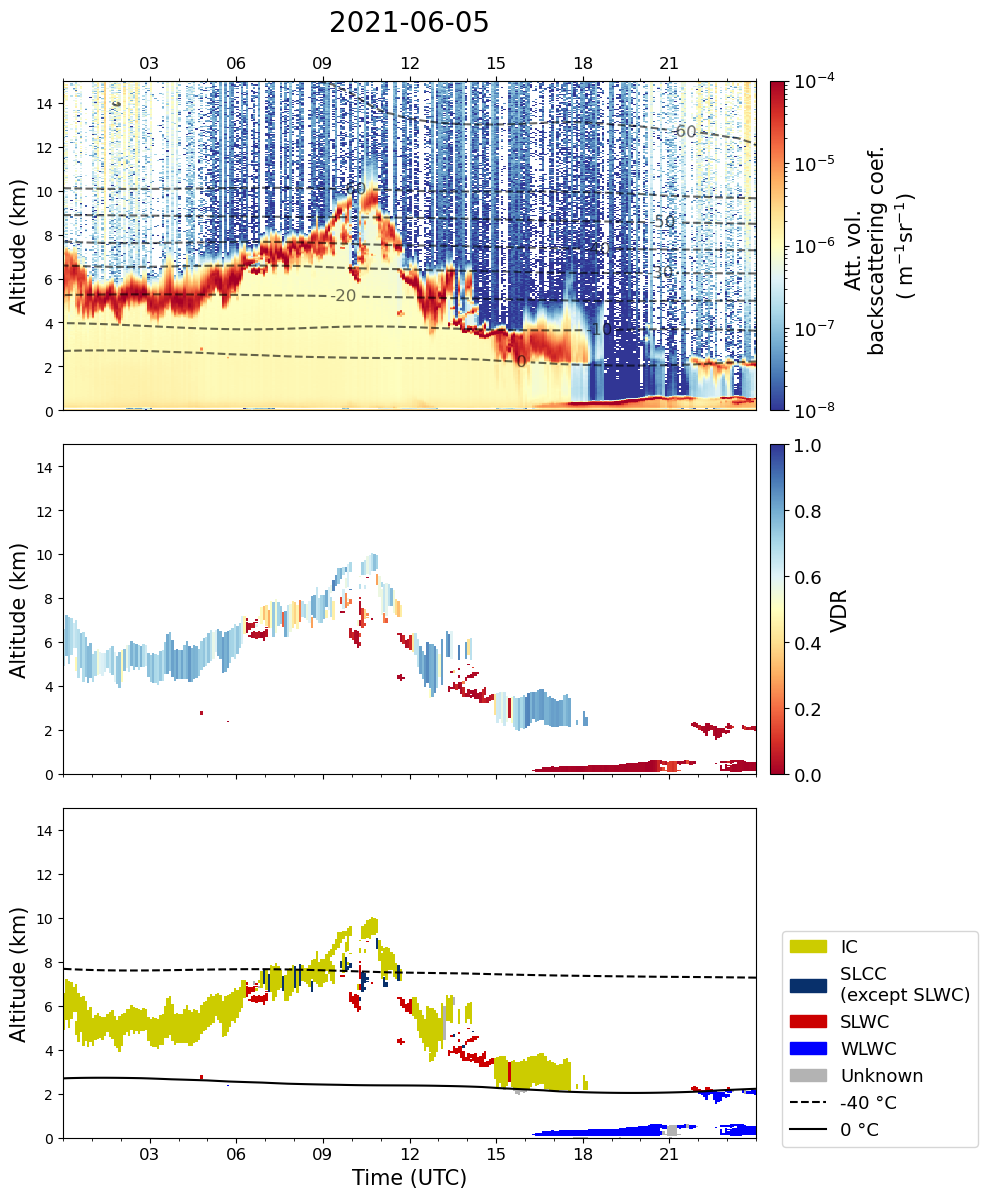

In [21]:
####################### Plotting

fig, axes = plt.subplots(3,figsize=(10,12))
(ax1, ax2, ax3) = axes

## Fig 1 - ALCF backscatter

Im1=ax1.imshow(ds['backscatter'].values[:].T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    interpolation='None',
    cmap='RdYlBu_r',
    norm=colors.LogNorm(vmin=1e-8,vmax=1e-4),
    
)

cax1 = ax1.inset_axes([1.02,0,0.02,1],transform=ax1.transAxes)

fig.colorbar(Im1,
        extend='neither',
        cax=cax1,
    ).set_label(label='Att. vol. \nbackscattering coef. \n( m$^{-1}$sr$^{-1}$)', size=15, labelpad=6)

ax1.set_ylabel('Altitude (km)', fontsize=15)
ax1.set_xticklabels([])
ax1.set_xticks(np.arange(36,288,36))
ax1.xaxis.set_minor_locator(MultipleLocator(12))
cax1.tick_params(labelsize=13)

CS=ax1.contour(ds['temp'].values[:].T,
            levels=[-60,-50,-40,-30,-20,-10,0],
            colors='k',
            alpha=0.6,
            linestyles='dashed',
            extent=(0, 288, 0, 15),
            )

ax1.clabel(CS,inline=True,fontsize=12,fmt='%.0f')

## Fig 2 - VDR raw data
    
# Im2=ax2.imshow(vdr[:].T,
Im2=ax2.imshow(ds['vdr_cm'].values[:].T,             
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    # cmap=cmap_vdr,
    cmap = 'RdYlBu'
)

ax2.set_xticklabels([])
ax2.set_xticks(np.arange(36,288,36))
ax2.xaxis.set_minor_locator(MultipleLocator(12))
ax2.set_ylabel('Altitude (km)', fontsize=15)

cax2 = ax2.inset_axes([1.02,0,0.02,1],transform=ax2.transAxes)

fig.colorbar(Im2,
        extend='neither',
        cax=cax2,
    ).set_label(label='VDR', size=15, labelpad=6)

cax2.tick_params(labelsize=13)




## Fig 3 - Reference (VDR) mask

Im3=ax3.imshow(ds['unknown'].values[:].T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap5
)

Im3=ax3.imshow(ds['ic'].values[:].T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap4
)

Im3=ax3.imshow(ds['slcc'].values[:].T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap1
)

Im3=ax3.imshow(ds['slwc'].values[:].T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap2
)

Im3=ax3.imshow(ds['wlwc'].values[:].T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap3
)



ax3.set_xticklabels([])
ax3.set_xticks(np.arange(36,288,36))
ax3.xaxis.set_minor_locator(MultipleLocator(12))
ax3.set_ylabel('Altitude (km)', fontsize=15)

ax3.contour(ds['temp'].values[:].T,
            levels=[-40,0],
            colors='k',
            linestyles=['dashed','solid'],
            extent=(0, 288, 0, 15),
            )


colour_labels = ['IC', 'SLCC \n(except SLWC)', 'SLWC', 'WLWC', 'Unknown']
patch_colors = [ c4, c1, c2, c3, c5]
patches_colours = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(5) ]

patch_linestyles = ['dashed', 'solid']
linestyle_labels = ['-40 \N{DEGREE SIGN}C', '0 \N{DEGREE SIGN}C']
patches_lines = [mlines.Line2D([],[],color='k',linestyle=patch_linestyles[i], label=linestyle_labels[i]) for i in range(2)] 
patches = patches_colours + patches_lines
ax3.legend(handles=patches, bbox_to_anchor=(1.025, 0.3), loc=6, fontsize=13)#,borderaxespad=0. )

ax3.set_xlabel('Time (UTC)', fontsize=15)

ax3.set_xticklabels([ '03',
                        '06',
                        '09',
                        '12',
                        '15',
                        '18',
                        '21'], fontsize=12)




ax1.xaxis.tick_top()
ax1.set_xticklabels([ '03',
                        '06',
                        '09',
                        '12',
                        '15',
                        '18',
                        '21'], fontsize=12)


ddate = date[:4]+'-'+date[4:6]+'-'+date[6:]
# ax1.text(0.5,1.2,'Z_'+TARGET+'   '+ddate,fontsize=30,transform=ax1.transAxes,ha='center')
ax1.text(0.5,1.15,ddate,fontsize=20,transform=ax1.transAxes,ha='center')

plt.tight_layout()
plt.savefig('/home/lukeew/Local_work/01_SLW_xgb/output/figs/vdr_class/{}.png'.format(date), dpi=300)
# plt.show()


### Saving

In [19]:
print('Date {} finished.'.format(date))

outfile = output_dir.format(date[:-2])+str(date)+'.nc'

# ds.to_netcdf(outfile, format='NETCDF4')

print('Wrote output to file for month',date)
print('  ---> ' + outfile)

Date 20210519 finished.
Wrote output to file for month 20210519
  ---> /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v2_reference/processed202105/20210519.nc


## List of dates

In [45]:
def getUnproDates():
    dates = [file[-11:-3].replace('-','') for file in sorted(glob.glob(vdr_mask_data_dir.format('*')+'/*.nc'))]
    unprocessed_dates = []
    for date in dates:
        if not os.path.exists(output_dir.format(date[:-2])+str(date)+'.nc'):
            unprocessed_dates+=[date]
    return unprocessed_dates

print(getUnproDates())


['20210506', '20210507', '20210508', '20210509', '20210510', '20210511', '20210512', '20210513', '20210514', '20210515', '20210516', '20210517', '20210518', '20210523', '20210524', '20210525', '20210526', '20210527', '20210528', '20210529', '20210530', '20210531', '20210601', '20210602', '20210603', '20210604', '20210605', '20210606', '20210607', '20210608', '20210609', '20210610', '20210611', '20210612', '20210613', '20210614', '20210615', '20210616', '20210617', '20210618', '20210619', '20210620', '20210621', '20210622', '20210623', '20210624', '20210625', '20210626', '20210627', '20210628', '20210629', '20210630', '20210701', '20210702', '20210703', '20210704', '20210705', '20210706', '20210707', '20210708', '20210709', '20210710', '20210711', '20210712', '20210713', '20210714', '20210715', '20210716', '20210719', '20210720', '20210721', '20210722', '20210723', '20210724', '20210725', '20210726', '20210727', '20210728', '20210729', '20210730', '20210731', '20210801', '20210802', '20

In [47]:
date = dates[-1]
# os.path.exists(output_dir.format(date[:-2])+str(date)+'.nc')
# output_dir.format(date[:-2])+str(date)+'.nc'
date

'20220121'